# Data quality before classifier tuning

Read completed server artifacts only. No PCA, MI, bootstrap or classifier is fitted here.
Set `IIVV_QUALITY` to the copied quality directory. Whole-cohort projections are descriptive;
they are not held-out performance evidence and never supply tuning features.


In [1]:
import json, os
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image, FileLink

REPO = Path.cwd()
if not (REPO / "run_revision.py").is_file():
    REPO = REPO.parent
assert (
    REPO / "run_revision.py"
).is_file(), "Start Jupyter in the repository or manuscript directory"
import sys

if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from revision.data import TASK_PROTOCOL, TASK_TITLES, TASK3_CAPTION


def csv(path, limit=None):
    path = Path(path)
    if not path.is_file():
        display(Markdown(f"Pending/unavailable: `{path.name}`"))
        return pd.DataFrame()
    try:
        table = pd.read_csv(path)
    except pd.errors.EmptyDataError:
        table = pd.DataFrame()
    display(table if limit is None else table.head(limit))
    return table


def images(paths):
    for path in paths:
        display(Markdown(f"**{path.name}**"))
        display(Image(filename=str(path)))
        if "cancer_vs_lr_hr" in str(path):
            display(Markdown(TASK3_CAPTION.replace("\n", " ")))


QUALITY = REPO / os.environ.get("IIVV_QUALITY", "results/revision-quality-v3")
quality_run = json.loads((QUALITY / "run_manifest.json").read_text())
assert (
    quality_run["config"].get("task_protocol") == TASK_PROTOCOL
), "Obsolete task protocol"
assert quality_run["status"] in {
    "quality_completed",
    "completed",
}, "Quality computation is incomplete"
assert not quality_run.get("synthetic"), "Synthetic quality is not clinical evidence"
from revision.data_quality import verify_quality

quality_manifest = verify_quality(QUALITY, quality_run["config"])
TASKS = quality_run["config"]["tasks"]
display(
    {
        "status": quality_run["status"],
        "cohort": quality_run["input_summary"],
        "protocol": TASK_PROTOCOL,
    }
)

{'status': 'quality_completed',
 'cohort': {'n_sites': 276,
  'n_patients': 100,
  'n_frequencies': 31,
  'n_patterns': 7728,
  'complex_available': True,
  'unmapped_pathologies': {'leukoplakia': 2,
   'basaloid scc': 1,
   'high-grade adenocarcinoma': 1}},
 'protocol': 'three-tasks-v1-lesion-only-task3'}

## Cohort, source agreement and clinical metadata

In [2]:
display(json.loads((QUALITY / "analysis_status.json").read_text()))
for name in [
    "site_inclusion_audit.csv",
    "source_quality_audit.csv",
    "class_by_location.csv",
    "covariate_cluster_associations.csv",
    "quality_cluster_associations.csv",
]:
    csv(QUALITY / "quality" / name)
display(json.loads((QUALITY / "quality/clinical_metadata_status.json").read_text()))
csv(QUALITY / "exploration/patient_pathology_overlap.csv")
csv(QUALITY / "exploration/cohort_pathology_counts.csv")

{'complex_feature_comparisons': 'available',
 'repeatability': 'available',
 'external_validation': 'not configured: no independent cohort assumed',
 'pathology_registration_blinding_mixed_sites': 'requires clinical records; no procedure inferred',
 'prospective_acquisition_and_hardware_validation': 'requires new measurements; only computation and coordinate requirements can be measured here',
 'requested_representations': ['magnitude', 'magnitude_phase']}

,sample_id,patient_id,site_id,pathology,raw_pathology,missing_percent,observed_missing_pattern_percent,source_file,location,prior_radiation,prior_surgery
0,0:0,0,0,Healthy,healthy,4.002761,2.355072,data/sample_0000.npz,oral tongue,No,No
1,0:1,0,1,Cancer,invasive carcinoma,17.037612,6.017081,data/sample_0001.npz,base tongue,No,No
2,1:0,1,0,Healthy,healthy,10.050035,3.623188,data/sample_0002.npz,floor of the mouth,No,No
3,1:1,1,1,Cancer,invasive carcinoma,2.135093,1.811594,data/sample_0003.npz,base tongue,No,No
4,1:2,1,2,NaN,leukoplakia,41.343168,18.038302,data/sample_0004.npz,anterior tongue,No,No
...,...,...,...,...,...,...,...,...,...,...,...
271,97:1,97,1,High-grade dysplasia,cis,4.132160,3.843168,data/sample_0271.npz,pharynx,Yes,No
272,98:0,98,0,Healthy,healthy,73.477398,47.968427,data/sample_0272.npz,right buccal mucosa,No,Yes
273,98:1,98,1,Non-malignant,benign,57.138544,39.868012,data/sample_0273.npz,oral tongue,No,Yes
274,99:0,99,0,Healthy,healthy,21.156832,4.917184,data/sample_0274.npz,buccal mucosa,NaN,NaN


,sample_id,py_idx,n_test_means,reported_quality_percent,mean_test_quality_percent,quality_mean_abs_difference,exported_equals_nanmean_of_test_means,observed_missing_percent,mean_test_missing_percent
0,0:0,0,3,4.002761,4.002761,0.0,True,2.355072,4.002761
1,0:1,1,3,17.037612,17.037612,0.0,True,6.017081,17.037612
2,1:0,2,3,10.050035,10.050035,0.0,True,3.623188,10.050035
3,1:1,3,3,2.135093,2.135093,0.0,True,1.811594,2.135093
4,1:2,4,3,41.343168,41.343168,0.0,True,18.038302,41.343168
...,...,...,...,...,...,...,...,...,...
271,97:1,271,3,4.132160,4.132160,0.0,True,3.843168,4.132160
272,98:0,272,3,73.477398,73.477398,0.0,True,47.968427,73.477398
273,98:1,273,3,57.138544,57.138544,0.0,True,39.868012,57.138544
274,99:0,274,3,21.156832,21.156832,0.0,True,4.917184,21.156832


,pathology,Unnamed: 1,alveolar ridge,anterior tongue,base tongue,buccal margin,buccal mucosa,floor of mouth,floor of the mouth,gingival mucosa,...,retromolar trigone / palate,right anterior tongue,right buccal mucosa,right retromolar trigone,right soft palate,soft palate,tonsil,tonsillar pillar,upper lip,ventral tongue
0,Cancer,0,3,0,9,0,3,1,15,2,...,0,0,0,0,0,1,16,0,1,1
1,Healthy,1,0,0,4,0,34,0,5,2,...,0,1,2,1,1,6,12,1,0,0
2,High-grade dysplasia,0,0,0,0,0,3,0,3,0,...,0,0,0,0,0,0,1,1,0,0
3,Non-malignant,0,0,1,2,1,4,0,3,0,...,0,0,0,0,0,2,1,0,0,2
4,NaN,0,0,1,0,0,0,0,0,0,...,1,0,0,0,0,0,1,0,0,0


,variable,level,status,wald_chi2,df,p_value,n_patients,method,reason,n_coefficients,covariance_rank,p_holm
0,prior_radiation,No,computed,0.404348,3.0,9.393428e-01,94,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00
1,prior_radiation,Yes,computed,0.404348,3.0,9.393428e-01,94,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00
2,location,oral tongue,computed,15.391316,3.0,1.511015e-03,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,5.137452e-02
3,location,base tongue,computed,9.982849,3.0,1.871249e-02,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,5.987996e-01
4,location,floor of the mouth,computed,5.576719,3.0,1.341213e-01,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00
5,location,anterior tongue,unavailable,NaN,NaN,NaN,100,NaN,singular or ill-conditioned patient-cluster co...,3.0,1.0,NaN
6,location,tonsil,computed,11.527527,3.0,9.190010e-03,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,3.032703e-01
7,location,buccal mucosa,computed,38.233536,3.0,2.522313e-08,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,8.828097e-07
8,location,soft palate,computed,9.183887,3.0,2.694333e-02,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,8.352432e-01
9,location,palate,computed,4.859811,3.0,1.823550e-01,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00


,factors,status,wald_chi2,df,p_value,n_patients,method,reason,n_coefficients,covariance_rank,p_holm
0,pathology,computed,62.937047,3.0,1.385257e-13,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,4.155770e-13
1,location,unavailable,NaN,NaN,NaN,100,NaN,singular or ill-conditioned patient-cluster co...,30.0,15.0,NaN
2,pathology+location,unavailable,NaN,NaN,NaN,100,NaN,singular or ill-conditioned patient-cluster co...,32.0,17.0,NaN


{'available': ['prior_radiation', 'location', 'prior_surgery'],
 'missing': ['age',
  'sex',
  'smoking',
  'alcohol',
  'inflammation',
  'treatment_history',
  'contact_pressure',
  'contact_angle'],
 'pathology_registration': 'requires clinical records',
 'mixed_histology_rule': 'requires clinical records',
 'pathology_blinding': 'requires clinical records',
 'contact_conditions': 'analyzed only if supplied; no controls assumed'}

,patient_id,n_sites,n_pathologies,n_raw_pathologies
0,0,2,2,2
1,1,3,2,3
2,10,1,1,1
3,11,2,2,2
4,12,2,2,2
...,...,...,...,...
95,95,3,3,3
96,96,2,2,2
97,97,2,2,2
98,98,2,2,2


,pathology,raw_pathology,n_sites,n_patients
0,Cancer,invasive carcinoma,96,70
1,Healthy,healthy,100,95
2,High-grade dysplasia,cis,5,4
3,High-grade dysplasia,high grade dysplasia,2,2
4,High-grade dysplasia,high-grade dysplasia,8,7
5,High-grade dysplasia,high-grade dysplasia /cis,1,1
6,High-grade dysplasia,high-grade dysplasia/ cis,8,4
7,High-grade dysplasia,moderate dysplasia,8,7
8,Non-malignant,benign,33,20
9,Non-malignant,mild dysplasia,11,8


,pathology,raw_pathology,n_sites,n_patients
0,Cancer,invasive carcinoma,96,70
1,Healthy,healthy,100,95
2,High-grade dysplasia,cis,5,4
3,High-grade dysplasia,high grade dysplasia,2,2
4,High-grade dysplasia,high-grade dysplasia,8,7
5,High-grade dysplasia,high-grade dysplasia /cis,1,1
6,High-grade dysplasia,high-grade dysplasia/ cis,8,4
7,High-grade dysplasia,moderate dysplasia,8,7
8,Non-malignant,benign,33,20
9,Non-malignant,mild dysplasia,11,8


## Missingness, spectrum properties and acquisition rejection

Acquisition rejection percentages differ from missing coordinates in averaged spectra.
Patients with multiple diagnoses do not demonstrate mixed histology within one footprint.


,sample_id,patient_id,site_id,pathology,raw_pathology,missing_percent,observed_missing_pattern_percent,source_file,location,prior_radiation,prior_surgery,nonfinite_coordinate_percent,median_magnitude_ohm
0,0:0,0,0,Healthy,healthy,4.002761,2.355072,data/sample_0000.npz,oral tongue,No,No,2.355072,168.203436
1,0:1,0,1,Cancer,invasive carcinoma,17.037612,6.017081,data/sample_0001.npz,base tongue,No,No,6.017081,291.491558
2,1:0,1,0,Healthy,healthy,10.050035,3.623188,data/sample_0002.npz,floor of the mouth,No,No,3.623188,439.635449
3,1:1,1,1,Cancer,invasive carcinoma,2.135093,1.811594,data/sample_0003.npz,base tongue,No,No,1.811594,103.578727
4,1:2,1,2,NaN,leukoplakia,41.343168,18.038302,data/sample_0004.npz,anterior tongue,No,No,18.038302,264.987049
5,2:0,2,0,Healthy,healthy,3.856108,2.238613,data/sample_0005.npz,base tongue,No,No,2.238613,162.834962
6,2:1,2,1,Cancer,invasive carcinoma,5.106970,2.251553,data/sample_0006.npz,base tongue,No,No,2.251553,182.341124
7,3:0,3,0,Healthy,healthy,3.722395,2.264493,data/sample_0007.npz,tonsil,No,Yes,2.264493,160.777463
8,3:1,3,1,Cancer,invasive carcinoma,2.273119,2.018634,data/sample_0008.npz,tonsil,No,Yes,2.018634,170.493313
9,4:0,4,0,Healthy,healthy,18.236715,10.041408,data/sample_0009.npz,floor of the mouth,No,No,10.041408,435.351111


,frequency_hz,nonfinite_percent,median_magnitude_ohm,magnitude_q25_ohm,magnitude_q75_ohm
0,100.000000,8.943715,453.225329,153.954590,1252.070485
1,125.892541,8.943715,440.124699,150.022414,1209.342655
2,158.489319,8.943715,430.873783,147.304416,1177.861547
3,199.526231,8.943715,421.129206,144.665907,1144.677852
4,251.188643,8.943715,410.379603,141.904225,1107.892924
5,316.227766,8.943715,398.510992,138.884220,1066.905878
6,398.107171,8.943715,385.251012,135.522090,1021.998250
7,501.187234,8.943715,368.659978,131.284160,964.624019
8,630.957344,8.943715,355.102590,126.652166,924.038829
9,794.328235,8.943715,339.774002,123.618864,869.230397


,pattern_index_0based,nonfinite_percent,I1,I2,V1,V2
0,0,3.985507,26,27,1,2
1,1,2.898551,26,27,1,3
2,2,5.434783,26,27,1,4
3,3,5.797101,26,27,1,5
4,4,6.159420,26,27,1,6
5,5,4.347826,26,27,1,7
6,6,5.072464,26,27,1,8
7,7,6.159420,26,27,1,9
8,8,5.797101,26,27,1,10
9,9,6.521739,26,27,1,11


,mask,frequency_hz,n_patterns,nonfinite_percent
0,All,100.000000,7728,8.943715
1,All,125.892541,7728,8.943715
2,All,158.489319,7728,8.943715
3,All,199.526231,7728,8.943715
4,All,251.188643,7728,8.943715
5,All,316.227766,7728,8.943715
6,All,398.107171,7728,8.943715
7,All,501.187234,7728,8.943715
8,All,630.957344,7728,8.943715
9,All,794.328235,7728,8.943715


**quality-overview.png**

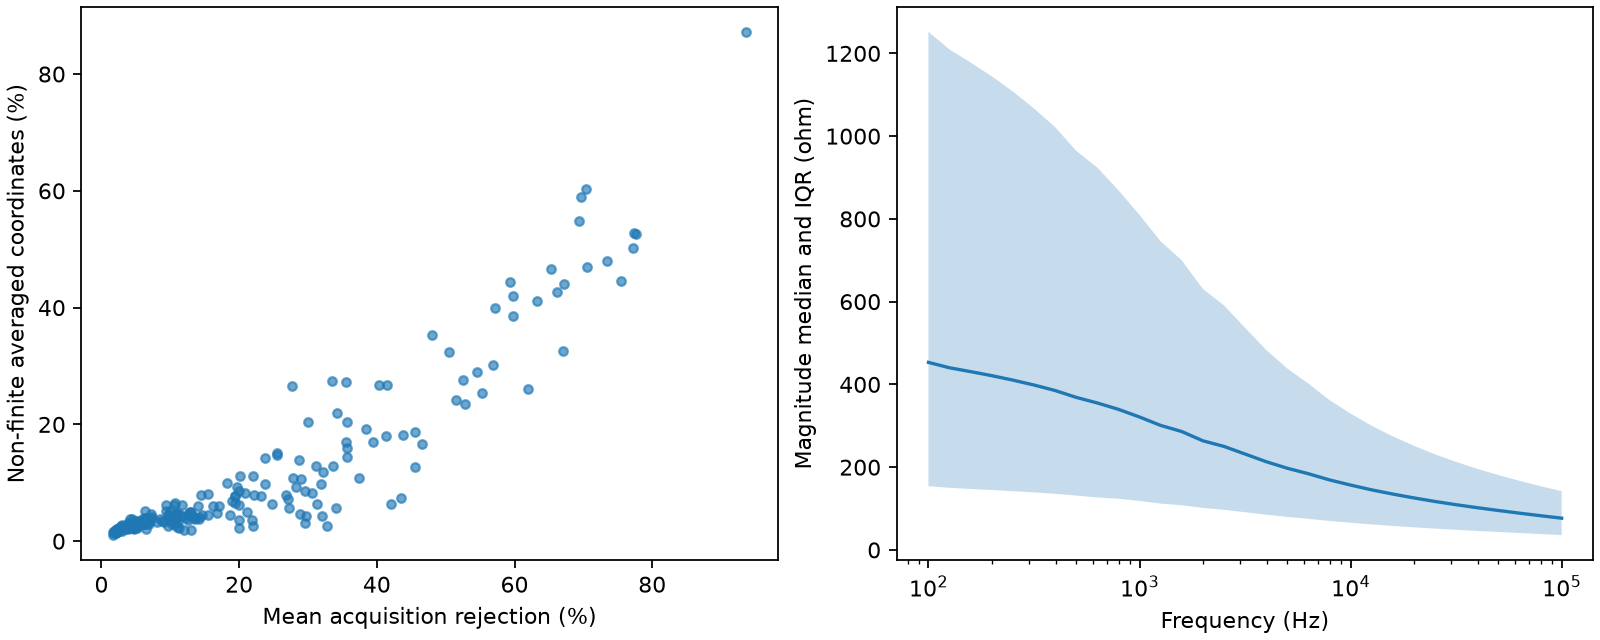

**mask-frequency-quality.png**

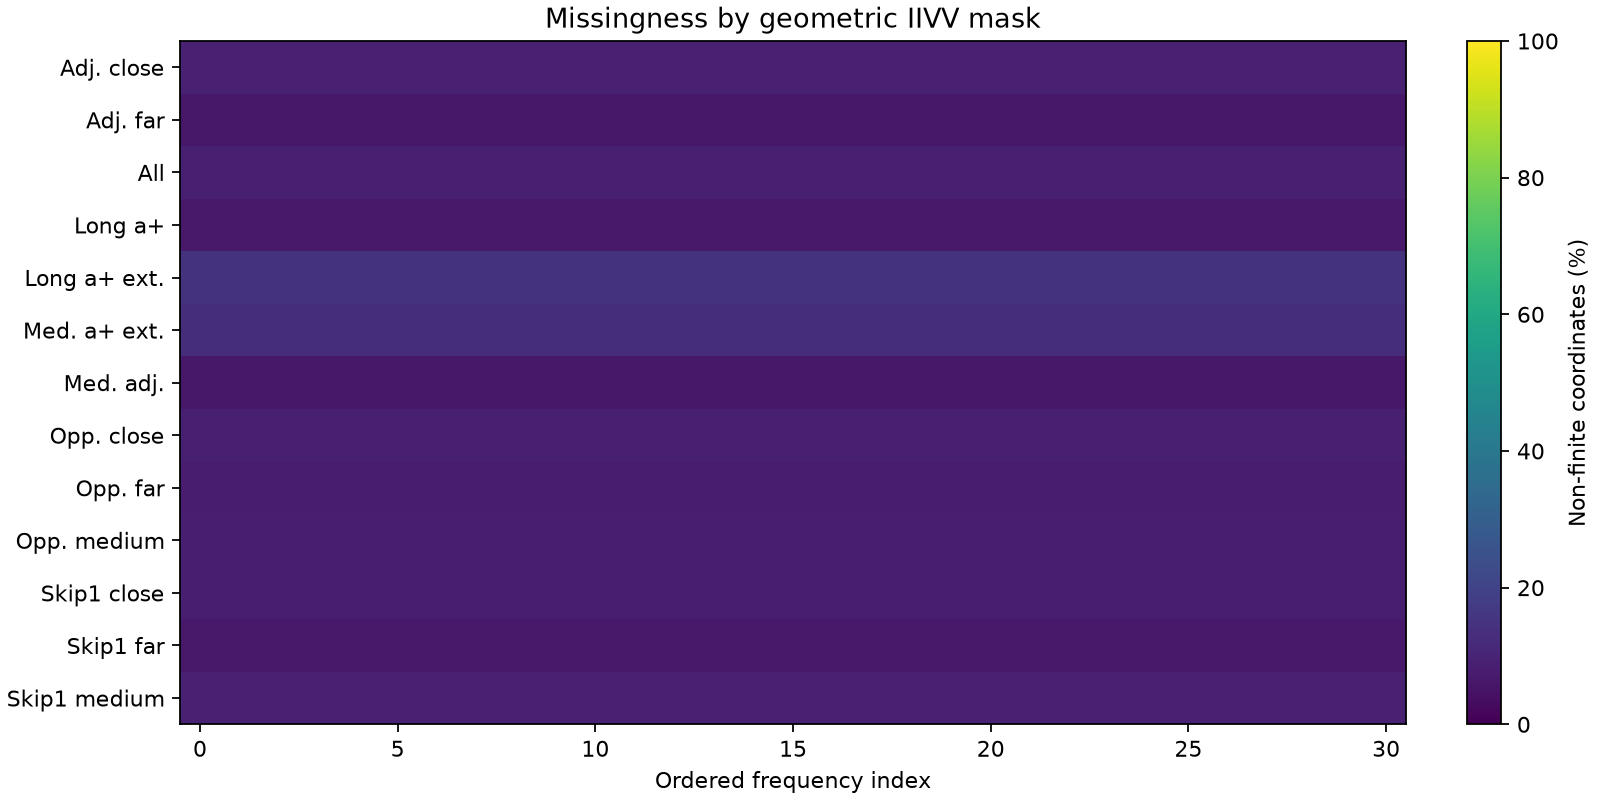

In [3]:
for name in [
    "site_quality.csv",
    "frequency_quality.csv",
    "pattern_quality.csv",
    "mask_frequency_quality.csv",
]:
    csv(QUALITY / "exploration" / name, 40)
images([QUALITY / "exploration/quality-overview.png"])
images([QUALITY / "exploration/mask-frequency-quality.png"])

## Task populations and quality retention

Cutoffs here are descriptive audits; they do not select classifier preprocessing.
Task 3 Low-grade dysplasia includes normal/benign tissue and mild dysplasia;
High-grade dysplasia includes moderate/severe dysplasia and CIS. Healthy sites are excluded.


,task,class_name,cutoff,total_sites,retained_sites,total_patients,retained_patients
0,healthy_vs_cancer,Cancer,0.000000,96,0,70,0
1,healthy_vs_cancer,Healthy,0.000000,100,0,95,0
2,healthy_vs_cancer,Cancer,20.000000,96,89,70,65
3,healthy_vs_cancer,Healthy,20.000000,100,54,95,53
4,healthy_vs_cancer,Cancer,40.000000,96,96,70,70
5,healthy_vs_cancer,Healthy,40.000000,100,75,95,74
6,healthy_vs_cancer,Cancer,60.000000,96,96,70,70
7,healthy_vs_cancer,Healthy,60.000000,100,90,95,88
8,healthy_vs_cancer,Cancer,80.000000,96,96,70,70
9,healthy_vs_cancer,Healthy,80.000000,100,99,95,94


### Task 1: Healthy vs Cancer

,sample_id,patient_id,site_id,pathology,raw_pathology,missing_percent,observed_missing_pattern_percent,source_file,location,prior_radiation,prior_surgery,class_name
0,0:0,0,0,Healthy,healthy,4.002761,2.355072,data/sample_0000.npz,oral tongue,No,No,Healthy
1,0:1,0,1,Cancer,invasive carcinoma,17.037612,6.017081,data/sample_0001.npz,base tongue,No,No,Cancer
2,1:0,1,0,Healthy,healthy,10.050035,3.623188,data/sample_0002.npz,floor of the mouth,No,No,Healthy
3,1:1,1,1,Cancer,invasive carcinoma,2.135093,1.811594,data/sample_0003.npz,base tongue,No,No,Cancer
4,2:0,2,0,Healthy,healthy,3.856108,2.238613,data/sample_0005.npz,base tongue,No,No,Healthy
...,...,...,...,...,...,...,...,...,...,...,...,...
191,96:0,96,0,Healthy,healthy,46.536404,16.718427,data/sample_0268.npz,buccal mucosa,No,Yes,Healthy
192,97:0,97,0,Healthy,healthy,2.549172,2.122153,data/sample_0270.npz,soft palate,Yes,No,Healthy
193,98:0,98,0,Healthy,healthy,73.477398,47.968427,data/sample_0272.npz,right buccal mucosa,No,Yes,Healthy
194,99:0,99,0,Healthy,healthy,21.156832,4.917184,data/sample_0274.npz,buccal mucosa,NaN,NaN,Healthy


,sample_id,patient_id,site_id,pathology,raw_pathology,missing_percent,observed_missing_pattern_percent,source_file,location,prior_radiation,prior_surgery,task_class,included
0,0:0,0,0,Healthy,healthy,4.002761,2.355072,data/sample_0000.npz,oral tongue,No,No,Healthy,True
1,0:1,0,1,Cancer,invasive carcinoma,17.037612,6.017081,data/sample_0001.npz,base tongue,No,No,Cancer,True
2,1:0,1,0,Healthy,healthy,10.050035,3.623188,data/sample_0002.npz,floor of the mouth,No,No,Healthy,True
3,1:1,1,1,Cancer,invasive carcinoma,2.135093,1.811594,data/sample_0003.npz,base tongue,No,No,Cancer,True
4,1:2,1,2,NaN,leukoplakia,41.343168,18.038302,data/sample_0004.npz,anterior tongue,No,No,NaN,False
5,2:0,2,0,Healthy,healthy,3.856108,2.238613,data/sample_0005.npz,base tongue,No,No,Healthy,True
6,2:1,2,1,Cancer,invasive carcinoma,5.106970,2.251553,data/sample_0006.npz,base tongue,No,No,Cancer,True
7,3:0,3,0,Healthy,healthy,3.722395,2.264493,data/sample_0007.npz,tonsil,No,Yes,Healthy,True
8,3:1,3,1,Cancer,invasive carcinoma,2.273119,2.018634,data/sample_0008.npz,tonsil,No,Yes,Cancer,True
9,4:0,4,0,Healthy,healthy,18.236715,10.041408,data/sample_0009.npz,floor of the mouth,No,No,Healthy,True


**healthy_vs_cancer-quality-retention.png**

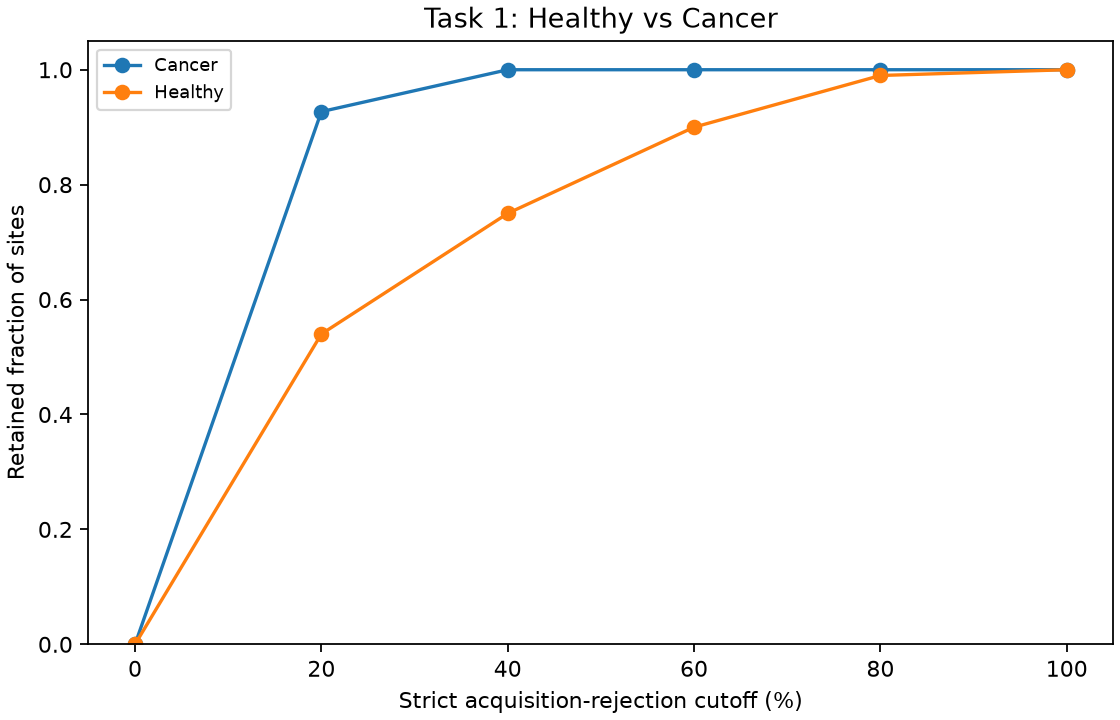

### Task 2: High risk vs Low risk

,sample_id,patient_id,site_id,pathology,raw_pathology,missing_percent,observed_missing_pattern_percent,source_file,location,prior_radiation,prior_surgery,class_name
0,0:0,0,0,Healthy,healthy,4.002761,2.355072,data/sample_0000.npz,oral tongue,No,No,Low risk
1,0:1,0,1,Cancer,invasive carcinoma,17.037612,6.017081,data/sample_0001.npz,base tongue,No,No,High risk
2,1:0,1,0,Healthy,healthy,10.050035,3.623188,data/sample_0002.npz,floor of the mouth,No,No,Low risk
3,1:1,1,1,Cancer,invasive carcinoma,2.135093,1.811594,data/sample_0003.npz,base tongue,No,No,High risk
4,2:0,2,0,Healthy,healthy,3.856108,2.238613,data/sample_0005.npz,base tongue,No,No,Low risk
...,...,...,...,...,...,...,...,...,...,...,...,...
267,97:1,97,1,High-grade dysplasia,cis,4.132160,3.843168,data/sample_0271.npz,pharynx,Yes,No,High risk
268,98:0,98,0,Healthy,healthy,73.477398,47.968427,data/sample_0272.npz,right buccal mucosa,No,Yes,Low risk
269,98:1,98,1,Non-malignant,benign,57.138544,39.868012,data/sample_0273.npz,oral tongue,No,Yes,Low risk
270,99:0,99,0,Healthy,healthy,21.156832,4.917184,data/sample_0274.npz,buccal mucosa,NaN,NaN,Low risk


,sample_id,patient_id,site_id,pathology,raw_pathology,missing_percent,observed_missing_pattern_percent,source_file,location,prior_radiation,prior_surgery,task_class,included
0,0:0,0,0,Healthy,healthy,4.002761,2.355072,data/sample_0000.npz,oral tongue,No,No,Low risk,True
1,0:1,0,1,Cancer,invasive carcinoma,17.037612,6.017081,data/sample_0001.npz,base tongue,No,No,High risk,True
2,1:0,1,0,Healthy,healthy,10.050035,3.623188,data/sample_0002.npz,floor of the mouth,No,No,Low risk,True
3,1:1,1,1,Cancer,invasive carcinoma,2.135093,1.811594,data/sample_0003.npz,base tongue,No,No,High risk,True
4,1:2,1,2,NaN,leukoplakia,41.343168,18.038302,data/sample_0004.npz,anterior tongue,No,No,NaN,False
5,2:0,2,0,Healthy,healthy,3.856108,2.238613,data/sample_0005.npz,base tongue,No,No,Low risk,True
6,2:1,2,1,Cancer,invasive carcinoma,5.106970,2.251553,data/sample_0006.npz,base tongue,No,No,High risk,True
7,3:0,3,0,Healthy,healthy,3.722395,2.264493,data/sample_0007.npz,tonsil,No,Yes,Low risk,True
8,3:1,3,1,Cancer,invasive carcinoma,2.273119,2.018634,data/sample_0008.npz,tonsil,No,Yes,High risk,True
9,4:0,4,0,Healthy,healthy,18.236715,10.041408,data/sample_0009.npz,floor of the mouth,No,No,Low risk,True


**highrisk_vs_lowrisk-quality-retention.png**

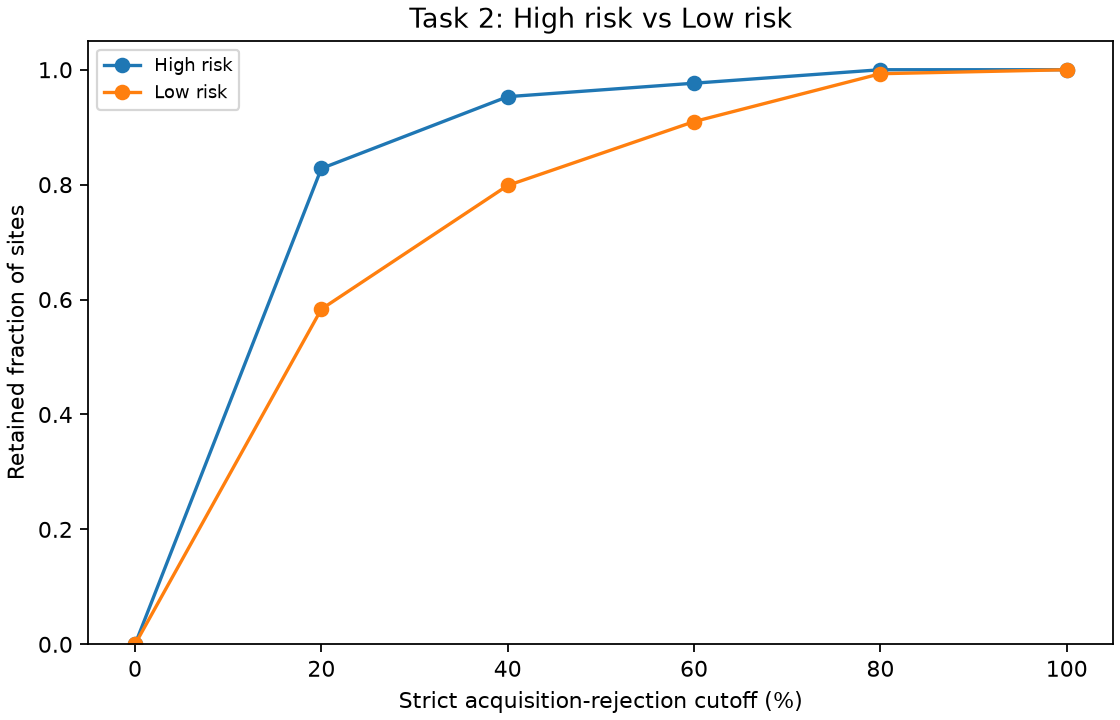

### Task 3: Lesion categorization

,sample_id,patient_id,site_id,pathology,raw_pathology,missing_percent,observed_missing_pattern_percent,source_file,location,prior_radiation,prior_surgery,class_name
0,0:1,0,1,Cancer,invasive carcinoma,17.037612,6.017081,data/sample_0001.npz,base tongue,No,No,Cancer
1,1:1,1,1,Cancer,invasive carcinoma,2.135093,1.811594,data/sample_0003.npz,base tongue,No,No,Cancer
2,2:1,2,1,Cancer,invasive carcinoma,5.106970,2.251553,data/sample_0006.npz,base tongue,No,No,Cancer
3,3:1,3,1,Cancer,invasive carcinoma,2.273119,2.018634,data/sample_0008.npz,tonsil,No,Yes,Cancer
4,4:1,4,1,Cancer,invasive carcinoma,2.570738,2.173913,data/sample_0010.npz,floor of the mouth,No,No,Cancer
...,...,...,...,...,...,...,...,...,...,...,...,...
167,95:2,95,2,Non-malignant,mild dysplasia,5.922188,2.963251,data/sample_0267.npz,palate,No,Yes,Low-grade dysplasia
168,96:1,96,1,High-grade dysplasia,moderate dysplasia,67.106625,32.518116,data/sample_0269.npz,buccal mucosa,No,Yes,High-grade dysplasia
169,97:1,97,1,High-grade dysplasia,cis,4.132160,3.843168,data/sample_0271.npz,pharynx,Yes,No,High-grade dysplasia
170,98:1,98,1,Non-malignant,benign,57.138544,39.868012,data/sample_0273.npz,oral tongue,No,Yes,Low-grade dysplasia


,sample_id,patient_id,site_id,pathology,raw_pathology,missing_percent,observed_missing_pattern_percent,source_file,location,prior_radiation,prior_surgery,task_class,included
0,0:0,0,0,Healthy,healthy,4.002761,2.355072,data/sample_0000.npz,oral tongue,No,No,NaN,False
1,0:1,0,1,Cancer,invasive carcinoma,17.037612,6.017081,data/sample_0001.npz,base tongue,No,No,Cancer,True
2,1:0,1,0,Healthy,healthy,10.050035,3.623188,data/sample_0002.npz,floor of the mouth,No,No,NaN,False
3,1:1,1,1,Cancer,invasive carcinoma,2.135093,1.811594,data/sample_0003.npz,base tongue,No,No,Cancer,True
4,1:2,1,2,NaN,leukoplakia,41.343168,18.038302,data/sample_0004.npz,anterior tongue,No,No,NaN,False
5,2:0,2,0,Healthy,healthy,3.856108,2.238613,data/sample_0005.npz,base tongue,No,No,NaN,False
6,2:1,2,1,Cancer,invasive carcinoma,5.106970,2.251553,data/sample_0006.npz,base tongue,No,No,Cancer,True
7,3:0,3,0,Healthy,healthy,3.722395,2.264493,data/sample_0007.npz,tonsil,No,Yes,NaN,False
8,3:1,3,1,Cancer,invasive carcinoma,2.273119,2.018634,data/sample_0008.npz,tonsil,No,Yes,Cancer,True
9,4:0,4,0,Healthy,healthy,18.236715,10.041408,data/sample_0009.npz,floor of the mouth,No,No,NaN,False


**cancer_vs_lr_hr-quality-retention.png**

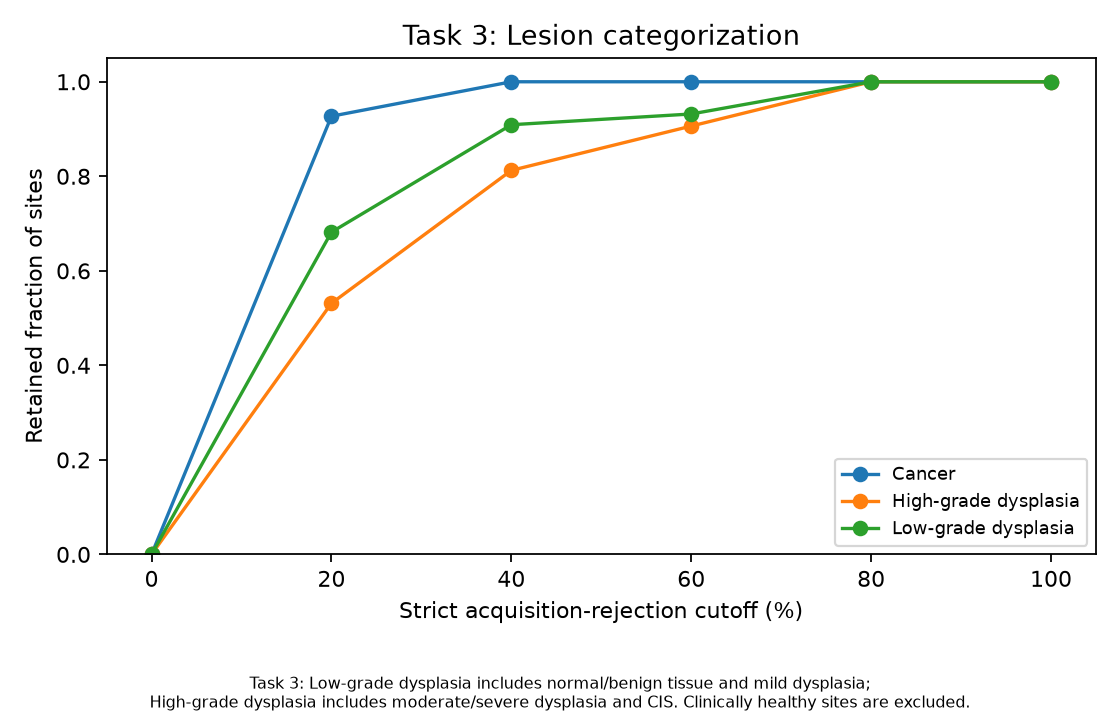

Task 3: Low-grade dysplasia includes normal/benign tissue and mild dysplasia; High-grade dysplasia includes moderate/severe dysplasia and CIS. Clinically healthy sites are excluded.

In [4]:
retention = csv(QUALITY / "exploration/task_quality_retention.csv")
for task in TASKS:
    display(Markdown(f"### {TASK_TITLES[task]}"))
    csv(QUALITY / "exploration" / f"{task}-inclusion.csv")
    csv(QUALITY / "exploration" / f"{task}-label-audit.csv", 30)
    images([QUALITY / "exploration" / f"{task}-quality-retention.png"])

## Unsupervised 2D PCA and exploratory MI-guided 2D PCA

One row represents a measurement site. Each frequency is summarized over finite IIVV
magnitudes, then log transformed. Patient-balanced mean imputation, scaling and SVD
are descriptive operations on this cohort. MI uses labels; the MI-guided plot must
not be interpreted as independent evidence of separation.


### Task 1: Healthy vs Cancer

**healthy_vs_cancer-mi-pca.png**

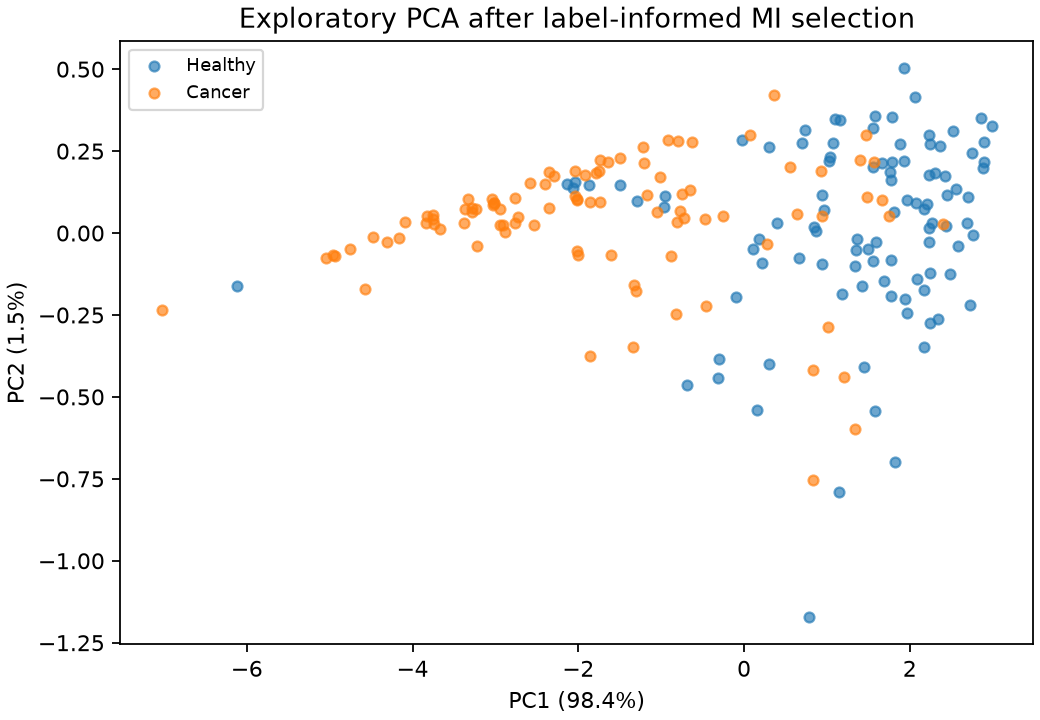

**healthy_vs_cancer-pca.png**

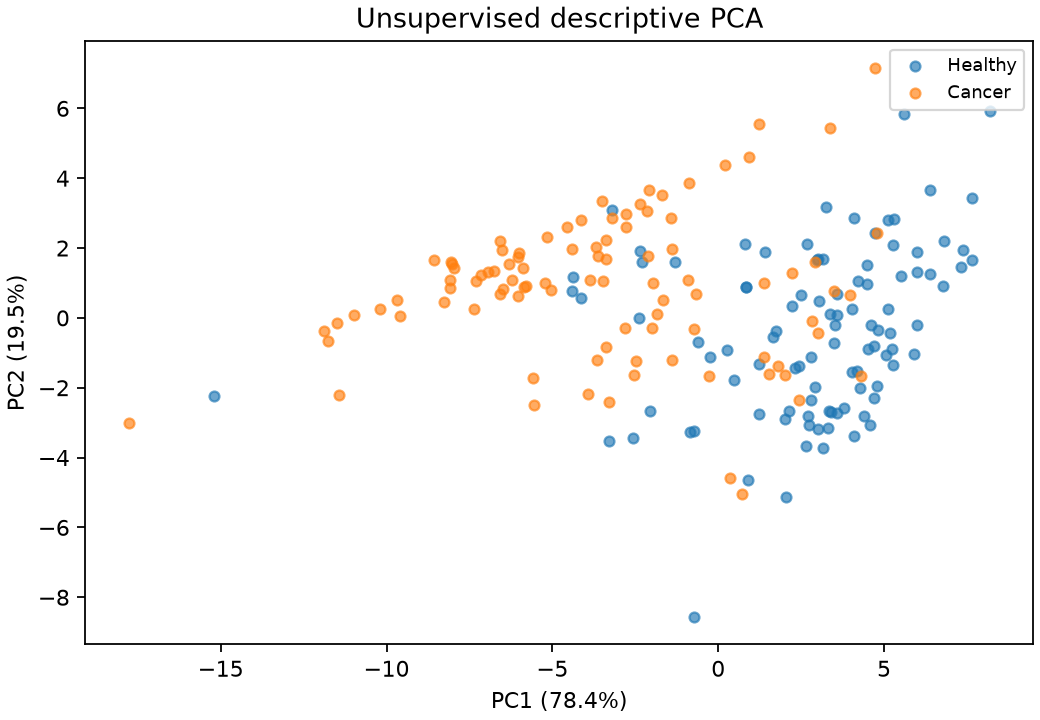

,frequency_hz,PC1_loading,PC2_loading,observed_patient_weight
0,100.000000,0.177220,-0.185908,1.0
1,125.892541,0.178092,-0.184205,1.0
2,158.489319,0.178862,-0.182403,1.0
3,199.526231,0.179792,-0.179990,1.0
4,251.188643,0.180906,-0.176844,1.0
5,316.227766,0.182235,-0.172745,1.0
6,398.107171,0.183785,-0.167523,1.0
7,501.187234,0.185489,-0.161124,1.0
8,630.957344,0.188397,-0.148906,1.0
9,794.328235,0.189617,-0.142892,1.0


,frequency_hz,PC1_loading,PC2_loading,observed_patient_weight
0,1000.000000,0.448114,-0.390003,1.0
1,794.328235,0.445718,-0.544505,1.0
2,2511.886432,0.448450,0.370131,1.0
3,1584.893192,0.449988,-0.072021,1.0
4,3162.277660,0.443771,0.639710,1.0


{'requested_patient_draws': 20,
 'valid_patient_draws': 20,
 'excluded_draws': 'Missing class or fewer than two patient draws for a class',
 'scope': 'Exploratory frequency summaries; no inference or classifier input'}

,frequency_hz,mutual_information_site,patient_draw_mean,patient_draw_std,patient_draw_count,rank_site
0,100.000000,0.274198,0.288586,0.047827,20,17.0
1,125.892541,0.299863,0.290974,0.044347,20,10.0
2,158.489319,0.293063,0.294465,0.044708,20,12.0
3,199.526231,0.285305,0.293944,0.046308,20,14.0
4,251.188643,0.296808,0.302042,0.048079,20,11.0
5,316.227766,0.290512,0.307932,0.049201,20,13.0
6,398.107171,0.281505,0.308719,0.049206,20,16.0
7,501.187234,0.284837,0.318142,0.046593,20,15.0
8,630.957344,0.309028,0.328082,0.046065,20,7.0
9,794.328235,0.345018,0.325278,0.044177,20,2.0


**healthy_vs_cancer-mutual-information.png**

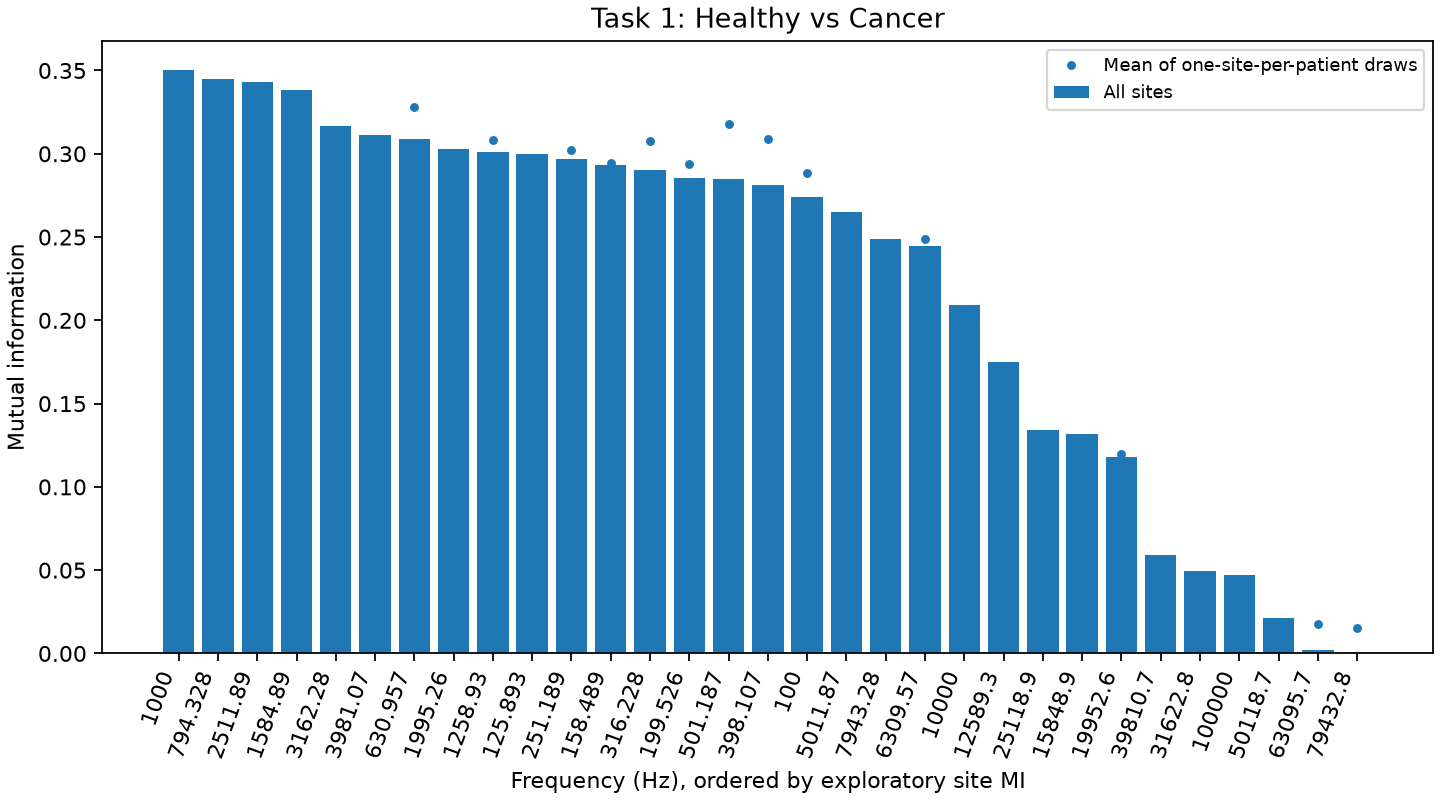

,draw,frequency_hz,mutual_information
0,0,100.000000,0.269851
1,0,125.892541,0.253991
2,0,158.489319,0.270170
3,0,199.526231,0.266769
4,0,251.188643,0.292930
5,0,316.227766,0.286922
6,0,398.107171,0.300331
7,0,501.187234,0.310221
8,0,630.957344,0.316711
9,0,794.328235,0.333238


### Task 2: High risk vs Low risk

**highrisk_vs_lowrisk-mi-pca.png**

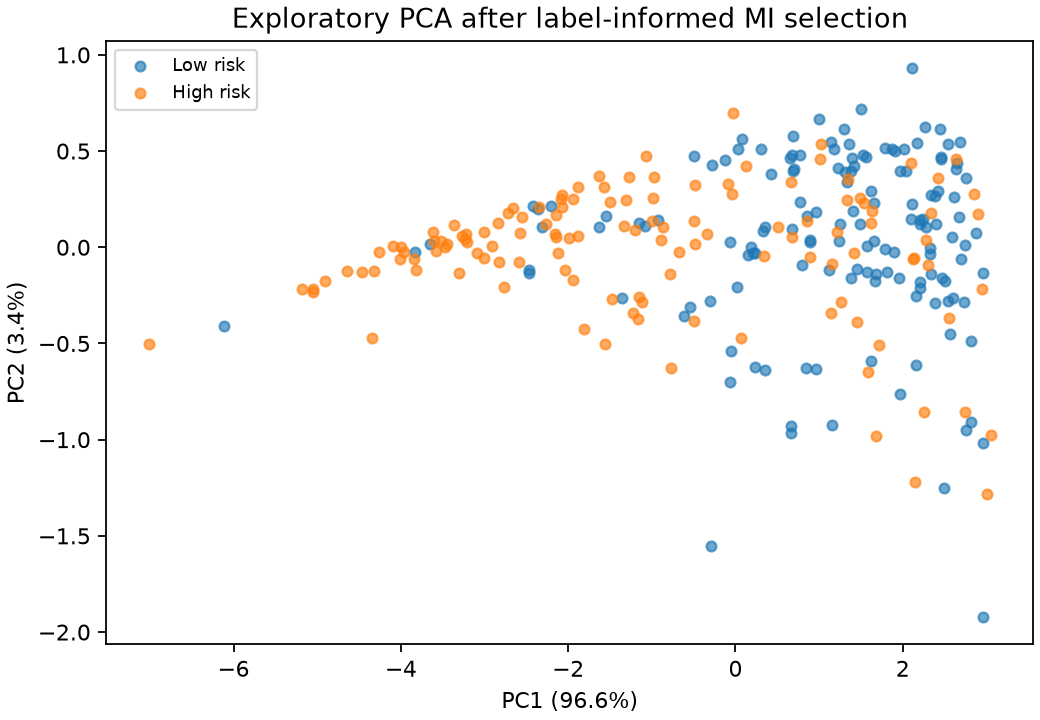

**highrisk_vs_lowrisk-pca.png**

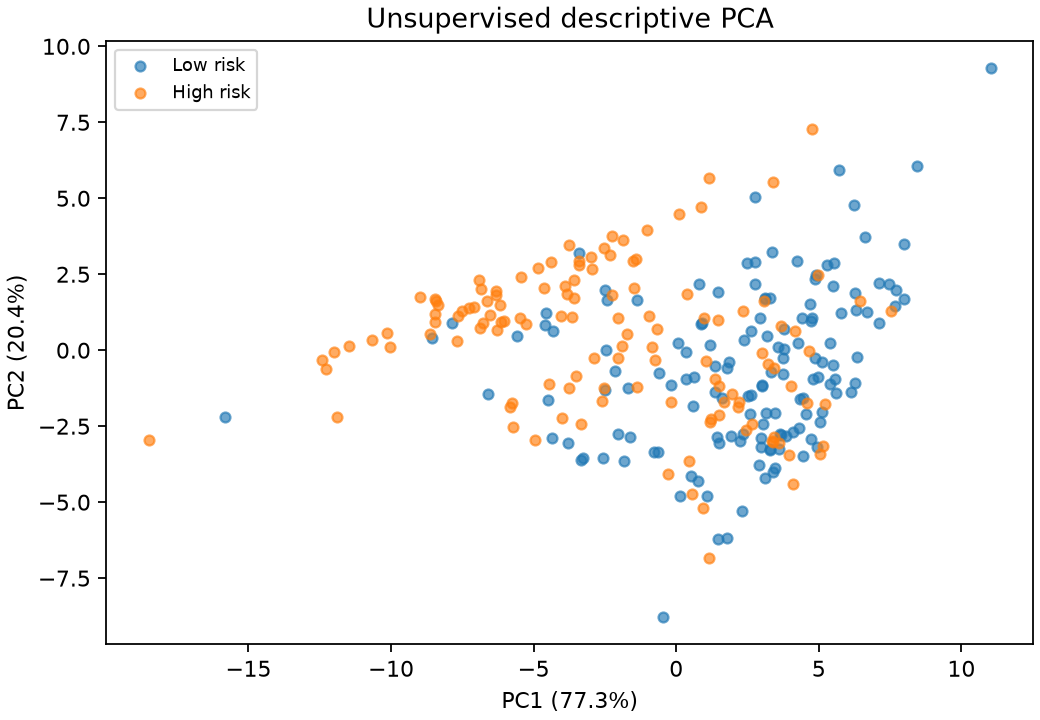

,frequency_hz,PC1_loading,PC2_loading,observed_patient_weight
0,100.000000,0.178489,-0.179219,1.0
1,125.892541,0.179562,-0.177308,1.0
2,158.489319,0.180380,-0.175631,1.0
3,199.526231,0.181328,-0.173463,1.0
4,251.188643,0.182437,-0.170688,1.0
5,316.227766,0.183740,-0.167096,1.0
6,398.107171,0.185251,-0.162490,1.0
7,501.187234,0.186979,-0.156465,1.0
8,630.957344,0.189544,-0.146710,1.0
9,794.328235,0.190831,-0.140760,1.0


,frequency_hz,PC1_loading,PC2_loading,observed_patient_weight
0,794.328235,0.454442,0.085951,1.0
1,3162.277660,0.426143,0.852366,1.0
2,125.892541,0.450956,-0.323947,1.0
3,199.526231,0.452291,-0.268388,1.0
4,158.489319,0.451615,-0.298516,1.0


{'requested_patient_draws': 20,
 'valid_patient_draws': 20,
 'excluded_draws': 'Missing class or fewer than two patient draws for a class',
 'scope': 'Exploratory frequency summaries; no inference or classifier input'}

,frequency_hz,mutual_information_site,patient_draw_mean,patient_draw_std,patient_draw_count,rank_site
0,100.000000,0.164293,0.169730,0.047849,20,8.0
1,125.892541,0.195019,0.180521,0.052084,20,3.0
2,158.489319,0.180597,0.179083,0.051147,20,5.0
3,199.526231,0.185200,0.181999,0.049911,20,4.0
4,251.188643,0.161504,0.185748,0.044869,20,9.0
5,316.227766,0.158817,0.181368,0.047759,20,11.0
6,398.107171,0.135942,0.179972,0.041801,20,14.0
7,501.187234,0.139699,0.182596,0.048832,20,12.0
8,630.957344,0.167065,0.185945,0.046536,20,7.0
9,794.328235,0.229088,0.188710,0.050452,20,1.0


**highrisk_vs_lowrisk-mutual-information.png**

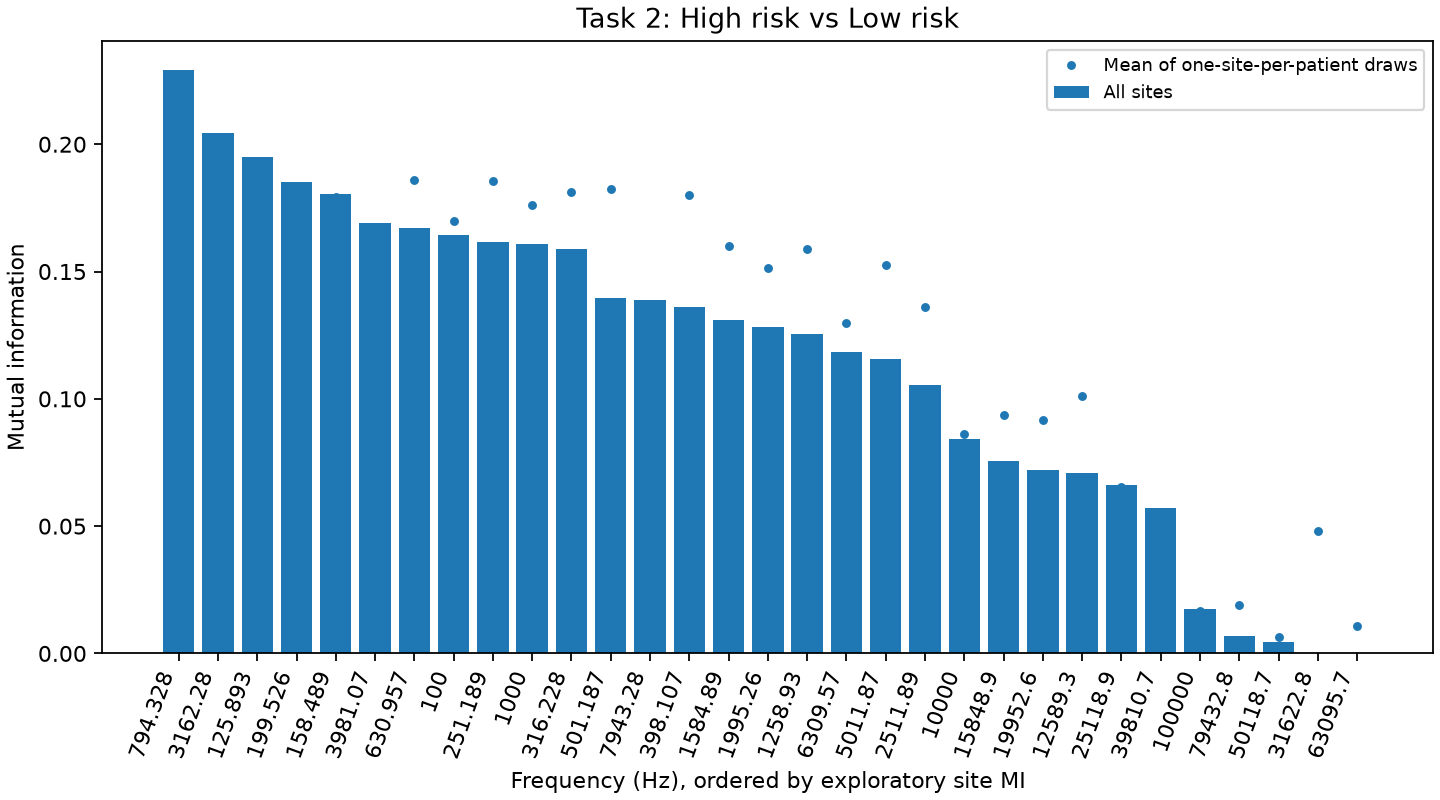

,draw,frequency_hz,mutual_information
0,0,100.000000,0.134438
1,0,125.892541,0.126039
2,0,158.489319,0.135427
3,0,199.526231,0.149016
4,0,251.188643,0.139160
5,0,316.227766,0.168010
6,0,398.107171,0.167478
7,0,501.187234,0.125158
8,0,630.957344,0.158908
9,0,794.328235,0.168269


### Task 3: Lesion categorization

**cancer_vs_lr_hr-mi-pca.png**

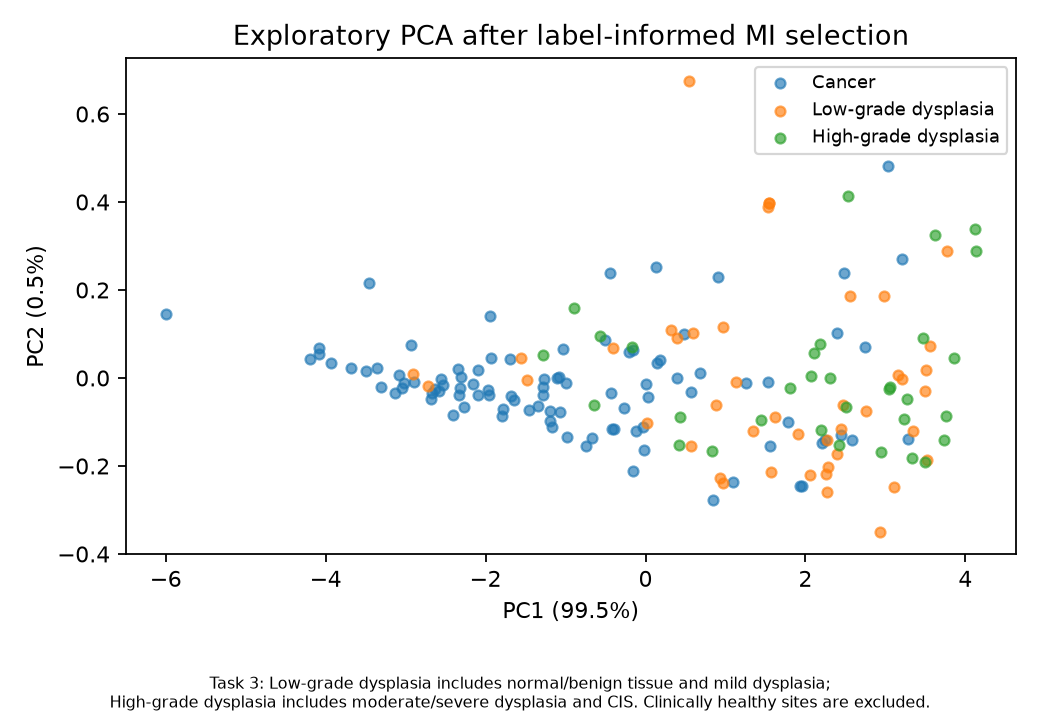

Task 3: Low-grade dysplasia includes normal/benign tissue and mild dysplasia; High-grade dysplasia includes moderate/severe dysplasia and CIS. Clinically healthy sites are excluded.

**cancer_vs_lr_hr-pca.png**

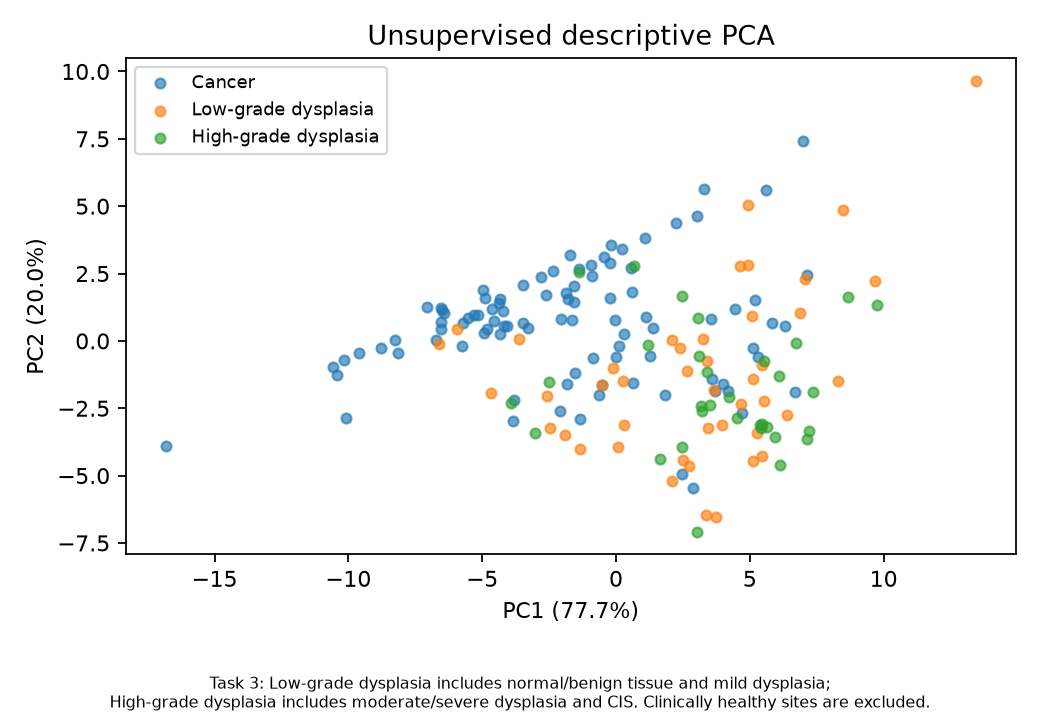

Task 3: Low-grade dysplasia includes normal/benign tissue and mild dysplasia; High-grade dysplasia includes moderate/severe dysplasia and CIS. Clinically healthy sites are excluded.

,frequency_hz,PC1_loading,PC2_loading,observed_patient_weight
0,100.000000,0.180254,-0.171645,1.0
1,125.892541,0.181314,-0.169441,1.0
2,158.489319,0.182051,-0.167821,1.0
3,199.526231,0.182891,-0.165798,1.0
4,251.188643,0.183871,-0.163244,1.0
5,316.227766,0.185017,-0.160002,1.0
6,398.107171,0.186349,-0.155850,1.0
7,501.187234,0.187868,-0.150404,1.0
8,630.957344,0.189992,-0.142543,1.0
9,794.328235,0.191149,-0.137008,1.0


,frequency_hz,PC1_loading,PC2_loading,observed_patient_weight
0,1000.000000,0.446831,-0.518577,1.0
1,794.328235,0.447989,-0.253274,1.0
2,125.892541,0.444835,0.791092,1.0
3,630.957344,0.448190,-0.150671,1.0
4,501.187234,0.448214,0.135657,1.0


{'requested_patient_draws': 20,
 'valid_patient_draws': 20,
 'excluded_draws': 'Missing class or fewer than two patient draws for a class',
 'scope': 'Exploratory frequency summaries; no inference or classifier input'}

,frequency_hz,mutual_information_site,patient_draw_mean,patient_draw_std,patient_draw_count,rank_site
0,100.000000,0.227975,0.237599,0.047091,20,6.0
1,125.892541,0.254131,0.246137,0.039753,20,3.0
2,158.489319,0.207039,0.239290,0.038808,20,10.0
3,199.526231,0.210323,0.248136,0.043405,20,9.0
4,251.188643,0.227625,0.250510,0.039866,20,7.0
5,316.227766,0.222558,0.249994,0.043503,20,8.0
6,398.107171,0.178636,0.229475,0.044434,20,16.0
7,501.187234,0.229389,0.254843,0.055339,20,5.0
8,630.957344,0.231444,0.238982,0.049216,20,4.0
9,794.328235,0.258660,0.234612,0.054859,20,2.0


**cancer_vs_lr_hr-mutual-information.png**

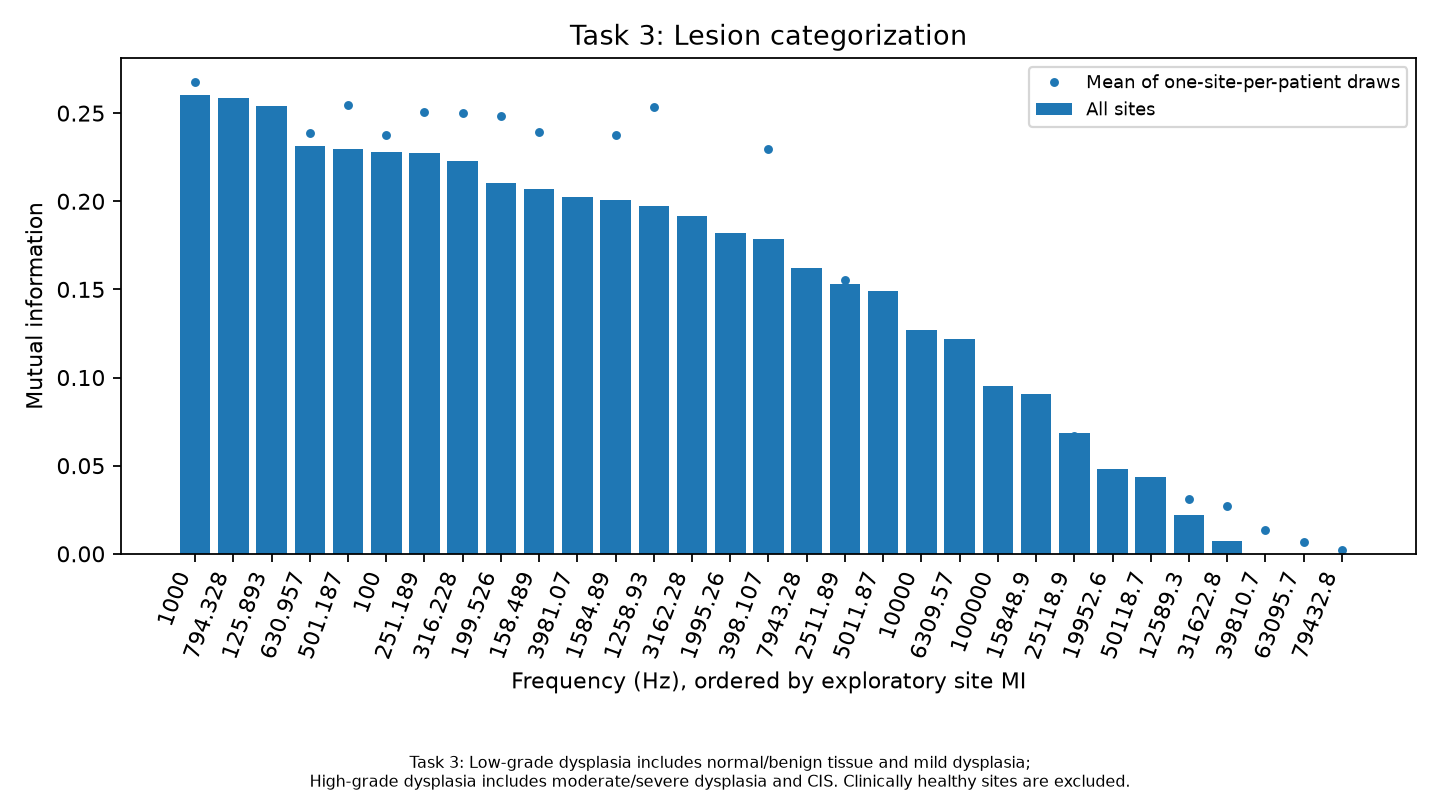

Task 3: Low-grade dysplasia includes normal/benign tissue and mild dysplasia; High-grade dysplasia includes moderate/severe dysplasia and CIS. Clinically healthy sites are excluded.

,draw,frequency_hz,mutual_information
0,0,100.000000,0.200723
1,0,125.892541,0.223935
2,0,158.489319,0.188988
3,0,199.526231,0.187528
4,0,251.188643,0.211797
5,0,316.227766,0.213192
6,0,398.107171,0.186611
7,0,501.187234,0.183654
8,0,630.957344,0.190744
9,0,794.328235,0.171036


In [5]:
for task in TASKS:
    display(Markdown(f"### {TASK_TITLES[task]}"))
    images(sorted((QUALITY / "exploration").glob(f"{task}-*pca.png")))
    csv(QUALITY / "exploration" / f"{task}-pca-loadings.csv")
    csv(QUALITY / "exploration" / f"{task}-mi-pca-loadings.csv")
    display(
        json.loads((QUALITY / "exploration" / f"{task}-mi-analysis.json").read_text())
    )
    ranking = csv(QUALITY / "exploration" / f"{task}-mutual-information.csv")
    images([QUALITY / "exploration" / f"{task}-mutual-information.png"])
    csv(QUALITY / "exploration" / f"{task}-mi-patient-draws.csv", 30)

## Repeatability of saved test means

ICC(2,1) and whole-patient bootstrap intervals describe the supplied test means.
They do not establish individual-burst repeatability or controlled contact conditions.


{'status': 'computed',
 'icc_endpoint': 'mean magnitude over available frequencies and patterns per acquisition replicate',
 'icc_model': 'ICC(2,1), absolute agreement; first three available test positions, complete sites; patient-cluster intervals',
 'n_replicates': 4,
 'caveat': 'Only supplied replicate units are analyzed. The two to four MATLAB Full_data spectra are test means, not nine bursts; within-burst repeatability is unavailable. Multiple sites within patients are clustered for intervals.'}

,class_name,n_sites,icc_2_1_absolute,balanced_icc_sites,balanced_icc_replicates,icc_ci_low,icc_ci_high,valid_cluster_bootstraps,between_site_sd
0,All,276,0.915723,274,3,0.886939,0.939942,1000,252.803002
1,Healthy,100,0.851177,100,3,0.774169,0.908951,1000,201.405185
2,Cancer,96,0.931818,95,3,0.890645,0.956170,1000,170.761702
3,Non-malignant,44,0.802229,44,3,0.577712,0.926342,1000,213.357189
4,High-grade dysplasia,32,0.877517,31,3,0.709385,0.954505,1000,233.354006


,sample_id,patient_id,pathology,mean_coordinate_cv,mean_magnitude,scalar_repeat_cv,n_finite_test_means,repositioning_sd
0,0:0,0,Healthy,0.391493,285.895051,0.114473,3,32.727278
1,0:1,0,Cancer,0.448475,560.416640,0.268196,3,150.301668
2,1:0,1,Healthy,0.217883,683.701282,0.115949,3,79.274190
3,1:1,1,Cancer,0.199558,136.386613,0.021110,3,2.879113
4,1:2,1,NaN,0.465265,504.000779,0.267388,3,134.763852
5,2:0,2,Healthy,0.417408,271.030391,0.246002,3,66.674124
6,2:1,2,Cancer,0.529017,323.274215,0.361243,3,116.780473
7,3:0,3,Healthy,0.441225,253.519550,0.237187,3,60.131538
8,3:1,3,Cancer,0.170567,223.859973,0.053033,3,11.871961
9,4:0,4,Healthy,0.157564,844.747393,0.045478,3,38.417248


**saved-test-mean-icc.png**

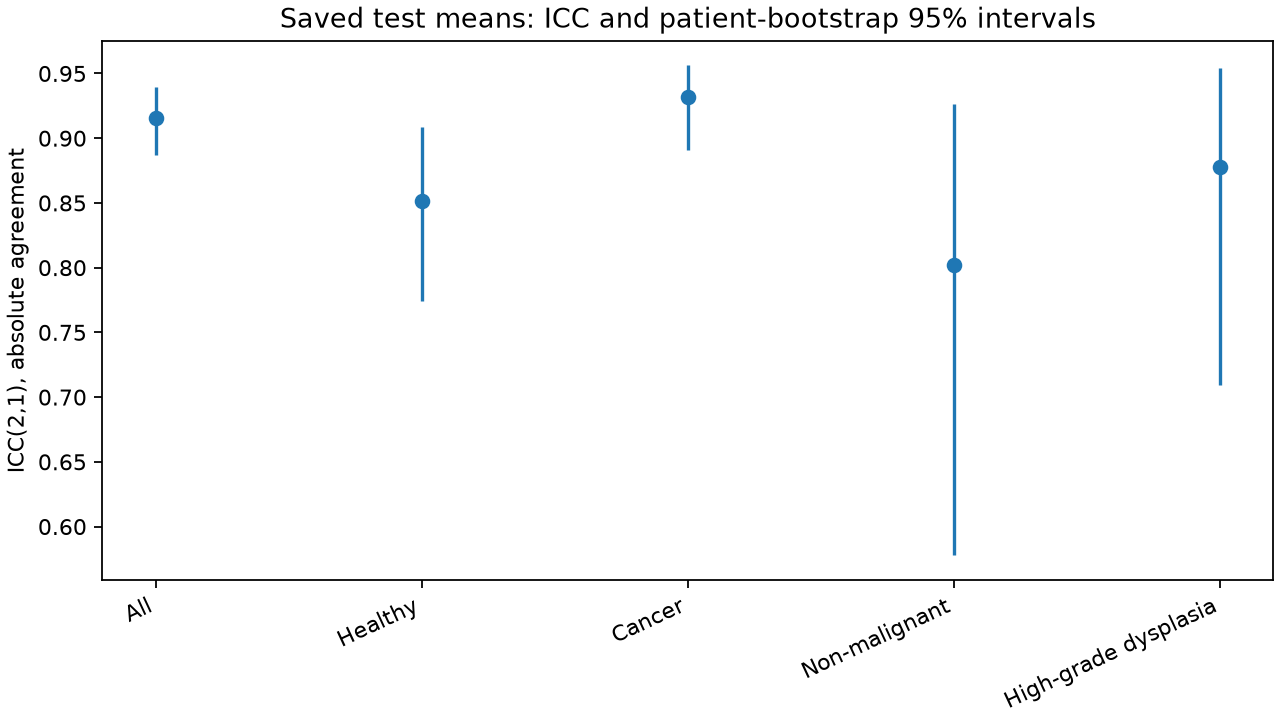

In [6]:
display(json.loads((QUALITY / "repeatability/status.json").read_text()))
csv(QUALITY / "repeatability/icc_and_inter_site_variability.csv")
csv(QUALITY / "repeatability/site_repeatability.csv", 40)
if (QUALITY / "exploration/saved-test-mean-icc.png").is_file():
    images([QUALITY / "exploration/saved-test-mean-icc.png"])

## Planned outer/inner CV demographics and raw pathology

In [7]:
for task in TASKS:
    display(Markdown(f"### {TASK_TITLES[task]}"))
    for name in [
        "cv_population_summary.csv",
        "cv_pathology_breakdown.csv",
        "cv_demographics_availability.csv",
        "cv_demographics_categorical.csv",
        "cv_demographics_numeric.csv",
        "cv_patient_groups.csv",
    ]:
        csv(QUALITY / "planned-splits" / task / name, 40)

### Task 1: Healthy vs Cancer

,task,evaluation,repeat,outer_fold,inner_fold,partition,population,cutoff,n_samples,n_patients,n_samples_before_quality,n_patients_before_quality,n_quality_excluded_samples,n_quality_excluded_patients,n_mixed_task_class_patients,samples_per_patient_min,samples_per_patient_median,samples_per_patient_max
0,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,166,81,166,81,0,0,55,1,2.0,6
1,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,quality_retained,60.000000,156,77,166,81,10,4,52,1,2.0,6
2,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,quality_retained,80.000000,165,80,166,81,1,1,55,1,2.0,6
3,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,quality_retained,100.000001,166,81,166,81,0,0,55,1,2.0,6
4,healthy_vs_cancer,nested_cv,0,0,-1,outer_test,unfiltered,NaN,30,17,30,17,0,0,12,1,2.0,3
5,healthy_vs_cancer,nested_cv,0,0,-1,outer_test,quality_retained,60.000000,30,17,30,17,0,0,12,1,2.0,3
6,healthy_vs_cancer,nested_cv,0,0,-1,outer_test,quality_retained,80.000000,30,17,30,17,0,0,12,1,2.0,3
7,healthy_vs_cancer,nested_cv,0,0,-1,outer_test,quality_retained,100.000001,30,17,30,17,0,0,12,1,2.0,3
8,healthy_vs_cancer,nested_cv,0,0,0,inner_train,unfiltered,NaN,130,63,130,63,0,0,43,1,2.0,6
9,healthy_vs_cancer,nested_cv,0,0,0,inner_train,quality_retained,60.000000,122,61,130,63,8,2,40,1,2.0,5


,task,evaluation,repeat,outer_fold,inner_fold,partition,population,cutoff,class_name,raw_pathology,n_samples,n_patients
0,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,Cancer,invasive carcinoma,82,57
1,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,Healthy,healthy,84,79
2,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,quality_retained,60.000000,Cancer,invasive carcinoma,82,57
3,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,quality_retained,60.000000,Healthy,healthy,74,72
4,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,quality_retained,80.000000,Cancer,invasive carcinoma,82,57
5,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,quality_retained,80.000000,Healthy,healthy,83,78
6,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,quality_retained,100.000001,Cancer,invasive carcinoma,82,57
7,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,quality_retained,100.000001,Healthy,healthy,84,79
8,healthy_vs_cancer,nested_cv,0,0,-1,outer_test,unfiltered,NaN,Cancer,invasive carcinoma,14,13
9,healthy_vs_cancer,nested_cv,0,0,-1,outer_test,unfiltered,NaN,Healthy,healthy,16,16


,task,evaluation,repeat,outer_fold,inner_fold,partition,population,cutoff,class_name,variable,available_in_source,n_samples,n_patients,n_recorded_samples,n_recorded_patients
0,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,age,False,166,81,0,0
1,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,sex,False,166,81,0,0
2,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,smoking,False,166,81,0,0
3,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,alcohol,False,166,81,0,0
4,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_radiation,True,166,81,151,76
5,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_surgery,True,166,81,151,76
6,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,location,True,166,81,165,80
7,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,inflammation,False,166,81,0,0
8,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,treatment_history,False,166,81,0,0
9,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,contact_pressure,False,166,81,0,0


,task,evaluation,repeat,outer_fold,inner_fold,partition,population,cutoff,class_name,variable,value,n_samples,n_patients,sample_denominator,patient_denominator
0,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,sex,<missing>,166,81,166,81
1,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,smoking,<missing>,166,81,166,81
2,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,alcohol,<missing>,166,81,166,81
3,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_radiation,<missing>,15,7,166,81
4,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_radiation,No,135,67,166,81
5,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_radiation,Yes,16,9,166,81
6,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_surgery,<missing>,15,7,166,81
7,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_surgery,No,113,55,166,81
8,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_surgery,Yes,38,21,166,81
9,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,location,<missing>,1,1,166,81


,task,evaluation,repeat,outer_fold,inner_fold,partition,population,cutoff,class_name,variable,...,n_observed,mean,sd,median,q25,q75,minimum,maximum,n_patients_with_conflicting_values,n_non_numeric_recorded_samples
0,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,age,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
1,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,age,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
2,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,contact_pressure,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
3,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,contact_pressure,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
4,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,contact_angle,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
5,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,contact_angle,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
6,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,Healthy,age,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
7,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,Healthy,age,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
8,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,Healthy,contact_pressure,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
9,healthy_vs_cancer,nested_cv,0,0,-1,outer_train,unfiltered,NaN,Healthy,contact_pressure,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0


... (11 outputs left out)

,task,evaluation,repeat,outer_fold,inner_fold,partition,population,cutoff,class_name,variable,available_in_source,n_samples,n_patients,n_recorded_samples,n_recorded_patients
0,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,age,False,142,77,0,0
1,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,sex,False,142,77,0,0
2,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,smoking,False,142,77,0,0
3,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,alcohol,False,142,77,0,0
4,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_radiation,True,142,77,120,73
5,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_surgery,True,142,77,120,73
6,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,location,True,142,77,142,77
7,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,inflammation,False,142,77,0,0
8,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,treatment_history,False,142,77,0,0
9,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,contact_pressure,False,142,77,0,0


,task,evaluation,repeat,outer_fold,inner_fold,partition,population,cutoff,class_name,variable,value,n_samples,n_patients,sample_denominator,patient_denominator
0,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,sex,<missing>,142,77,142,77
1,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,smoking,<missing>,142,77,142,77
2,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,alcohol,<missing>,142,77,142,77
3,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_radiation,<missing>,22,6,142,77
4,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_radiation,No,115,68,142,77
5,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_radiation,Yes,5,5,142,77
6,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_surgery,<missing>,22,6,142,77
7,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_surgery,No,90,55,142,77
8,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,prior_surgery,Yes,30,18,142,77
9,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,location,alveolar ridge,3,2,142,77


,task,evaluation,repeat,outer_fold,inner_fold,partition,population,cutoff,class_name,variable,...,n_observed,mean,sd,median,q25,q75,minimum,maximum,n_patients_with_conflicting_values,n_non_numeric_recorded_samples
0,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,age,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
1,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,age,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
2,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,contact_pressure,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
3,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,contact_pressure,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
4,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,contact_angle,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
5,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,All classes,contact_angle,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
6,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,Cancer,age,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
7,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,Cancer,age,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
8,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,Cancer,contact_pressure,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
9,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,Cancer,contact_pressure,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0


,task,evaluation,repeat,outer_fold,inner_fold,partition,population,cutoff,patient_id,n_samples,...,sex,smoking,alcohol,prior_radiation,prior_surgery,location,inflammation,treatment_history,contact_pressure,contact_angle
0,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,0,1,...,NaN,NaN,NaN,No,No,base tongue,NaN,NaN,NaN,NaN
1,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,1,1,...,NaN,NaN,NaN,No,No,base tongue,NaN,NaN,NaN,NaN
2,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,11,1,...,NaN,NaN,NaN,Yes,Yes,base tongue,NaN,NaN,NaN,NaN
3,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,13,1,...,NaN,NaN,NaN,No,No,tonsil,NaN,NaN,NaN,NaN
4,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,14,1,...,NaN,NaN,NaN,No,No,gingival mucosa,NaN,NaN,NaN,NaN
5,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,15,1,...,NaN,NaN,NaN,No,No,oral tongue,NaN,NaN,NaN,NaN
6,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,16,1,...,NaN,NaN,NaN,No,No,tonsil,NaN,NaN,NaN,NaN
7,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,17,1,...,NaN,NaN,NaN,No,Yes,oral tongue,NaN,NaN,NaN,NaN
8,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,19,1,...,NaN,NaN,NaN,Yes,Yes,base tongue,NaN,NaN,NaN,NaN
9,cancer_vs_lr_hr,nested_cv,0,0,-1,outer_train,unfiltered,NaN,21,1,...,NaN,NaN,NaN,No,No,oral tongue,NaN,NaN,NaN,NaN
